In [ ]:
print("My machine learning project has started!")

: 

In [1]:
print("My machine learning project has started!")

My machine learning project has started!


In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Download the Online Shoppers Purchasing Intention dataset
dataset = fetch_ucirepo(id=468)

# Separate the input features and target
X = dataset.data.features
y = dataset.data.targets

# Combine them into one table
df = pd.concat([X, y], axis=1)

# Display the first five rows
display(df.head())

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
print(df.shape)

(12330, 18)


In [4]:
print(df.columns)


Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue'],
      dtype='str')


In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTarget distribution:")
print(df["Revenue"].value_counts())

print("\nTarget percentages:")
print(df["Revenue"].value_counts(normalize=True) * 100)

Dataset shape: (12330, 18)

Column names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   P

In [6]:
# Convert Revenue from True/False to 1/0
df["Revenue"] = df["Revenue"].astype(int)

# Separate features and target again
X = df.drop("Revenue", axis=1)
y = df["Revenue"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (12330, 17)
Target shape: (12330,)


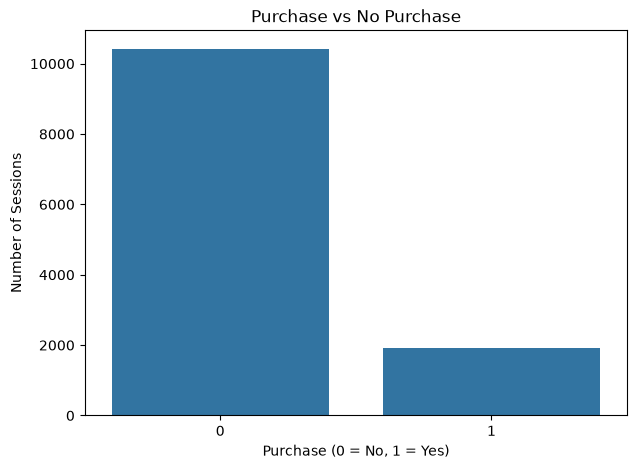

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Revenue")

plt.title("Purchase vs No Purchase")
plt.xlabel("Purchase (0 = No, 1 = Yes)")
plt.ylabel("Number of Sessions")

plt.show()

VisitorType
New_Visitor          24.911452
Other                18.823529
Returning_Visitor    13.932329
Name: Revenue, dtype: float64


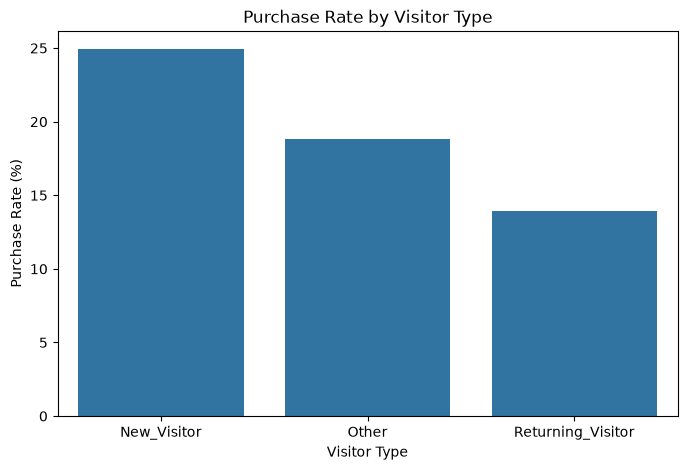

In [8]:
visitor_purchase = df.groupby("VisitorType")["Revenue"].mean() * 100

print(visitor_purchase)

plt.figure(figsize=(8, 5))

sns.barplot(x=visitor_purchase.index, y=visitor_purchase.values)

plt.title("Purchase Rate by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Purchase Rate (%)")

plt.show()

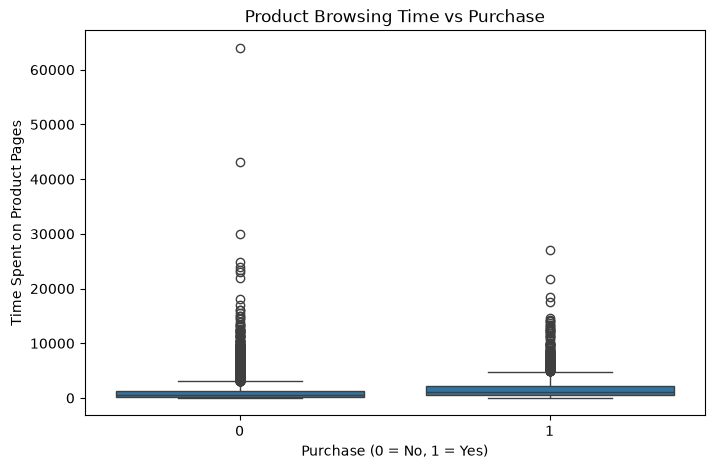

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Revenue", y="ProductRelated_Duration")

plt.title("Product Browsing Time vs Purchase")
plt.xlabel("Purchase (0 = No, 1 = Yes)")
plt.ylabel("Time Spent on Product Pages")

plt.show()


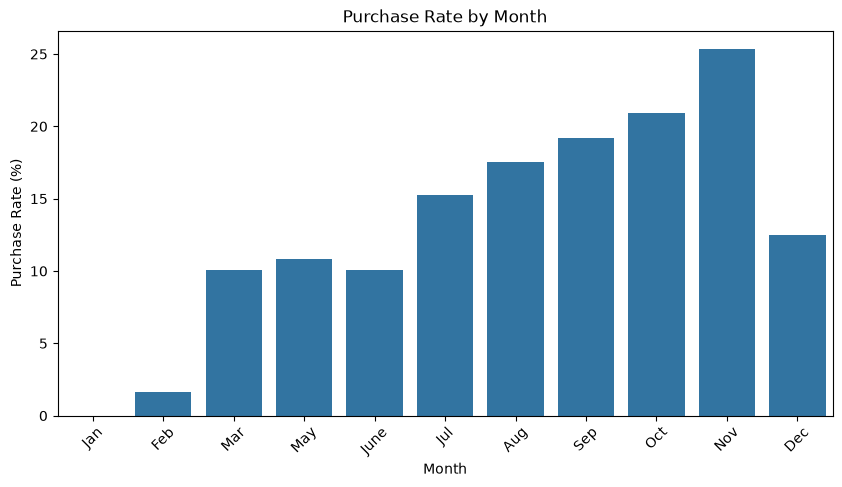

In [10]:
monthly_purchase = df.groupby("Month")["Revenue"].mean() * 100

month_order = [
   "Jan", "Feb", "Mar", "May", "June", "Jul",
    "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_purchase = monthly_purchase.reindex(month_order)

plt.figure(figsize=(10, 5))

sns.barplot(x=monthly_purchase.index, y=monthly_purchase.values)

plt.title("Purchase Rate by Month")
plt.xlabel("Month")
plt.ylabel("Purchase Rate (%)")
plt.xticks(rotation=45)

plt.show()

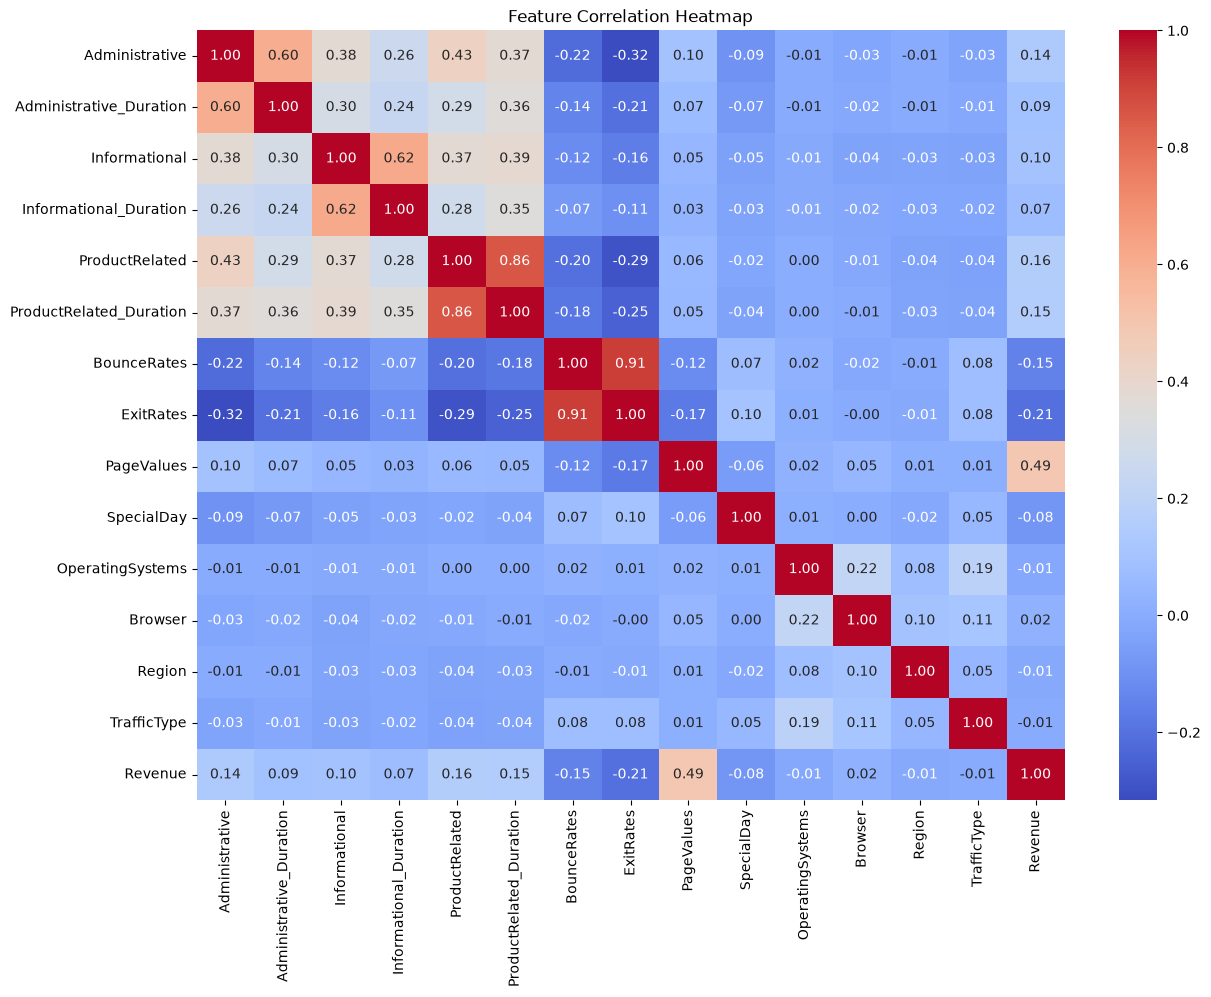

In [11]:
plt.figure(figsize=(14, 10))

numeric_df = df.select_dtypes(include=["number"])

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (9864, 17)
Testing features: (2466, 17)
Training targets: (9864,)
Testing targets: (2466,)


In [13]:
categorical_columns = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

numerical_columns = [
    column for column in X.columns
    if column not in categorical_columns
]

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

Numerical columns:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Prepare numerical columns
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Dummy Classifier": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )
}

In [16]:
pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

print("All model pipelines created!")

All model pipelines created!


In [17]:
from sklearn.model_selection import cross_validate, StratifiedKFold
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

results = []

for name, pipeline in pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean()
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC
0     Dummy Classifier    0.8453     0.0000  0.0000  0.0000   0.5000  0.1547
1  Logistic Regression    0.8528     0.5173  0.7647  0.6169   0.9044  0.6571
2        Decision Tree    0.8641     0.5590  0.5767  0.5675   0.7467  0.3878
3        Random Forest    0.8955     0.6464  0.7215  0.6814   0.9273  0.7331


In [18]:
# Import GridSearchCV to test different model configurations
from sklearn.model_selection import GridSearchCV

# Get the Random Forest pipeline we created earlier
random_forest_pipeline = pipelines["Random Forest"]

# Define the different parameter values we want to try
param_grid = {
    "classifier__n_estimators": [100, 200],  # Number of decision trees
    "classifier__max_depth": [None, 15],     # Maximum depth of each tree
    "classifier__min_samples_split": [2, 5]  # Minimum samples needed to split a node
}

# Create GridSearchCV to find the best combination of parameters
grid_search = GridSearchCV(
    estimator=random_forest_pipeline,  # Model we want to improve
    param_grid=param_grid,             # Parameter combinations to test
    scoring="average_precision",       # Use PR-AUC (Average Precision) to compare
    cv=3,                              # Use 3-fold cross-validation
    n_jobs=-1,                         # Use all available CPU cores
    verbose=1                          # Display progress while training
)

# Train and evaluate all parameter combinations using the training data
grid_search.fit(X_train, y_train)

# Display the best parameter combination found
print("Best parameters:")
print(grid_search.best_params_)

# Display its best cross-validation score
print("\nBest cross-validation PR-AUC:")
print(grid_search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters:
{'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

Best cross-validation PR-AUC:
0.7283931346211917


In [19]:
# Find the best model from the initial comparison
best_initial_name = results_df.loc[
    results_df["PR-AUC"].idxmax(),
    "Model"
]

best_initial_score = results_df["PR-AUC"].max()

# Compare the tuned Random Forest against the other models
if grid_search.best_score_ > best_initial_score:
    best_model = grid_search.best_estimator_
    best_model_name = "Tuned Random Forest"
else:
    best_model = pipelines[best_initial_name]
    best_model_name = best_initial_name

# Train the selected model on all training data
best_model.fit(X_train, y_train)

print("Selected model:", best_model_name)

Selected model: Random Forest


In [20]:
# Find the best model from the initial comparison
best_initial_name = results_df.loc[
    results_df["PR-AUC"].idxmax(),
    "Model"
]

best_initial_score = results_df["PR-AUC"].max()

# Compare the tuned Random Forest against the other models
if grid_search.best_score_ > best_initial_score:
    best_model = grid_search.best_estimator_
    best_model_name = "Tuned Random Forest"
else:
    best_model = pipelines[best_initial_name]
    best_model_name = best_initial_name

# Train the selected model on all training data
best_model.fit(X_train, y_train)

print("Selected model:", best_model_name)

Selected model: Random Forest


In [21]:
y_pred = best_model.predict(X_test)

# Get probability of purchase (class 1)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("Predictions completed!")

Predictions completed!


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

print("FINAL MODEL:", best_model_name)

print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

FINAL MODEL: Random Forest

Accuracy: 0.8901054339010543
Precision: 0.6312056737588653
Recall: 0.6989528795811518
F1 Score: 0.6633540372670808
ROC-AUC: 0.9190956276190572
PR-AUC: 0.7181570701624838

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.93      0.93      2084
           1       0.63      0.70      0.66       382

    accuracy                           0.89      2466
   macro avg       0.79      0.81      0.80      2466
weighted avg       0.90      0.89      0.89      2466



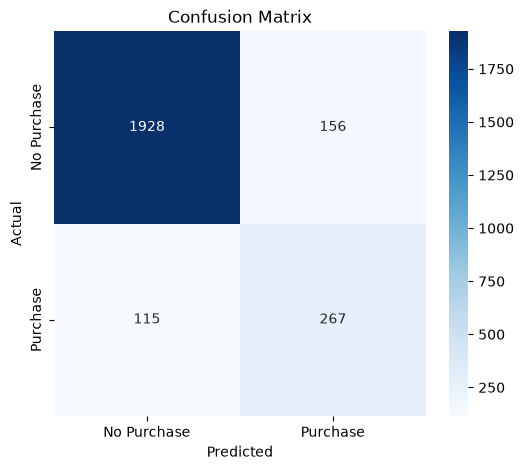

In [23]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Purchase", "Purchase"],
    yticklabels=["No Purchase", "Purchase"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

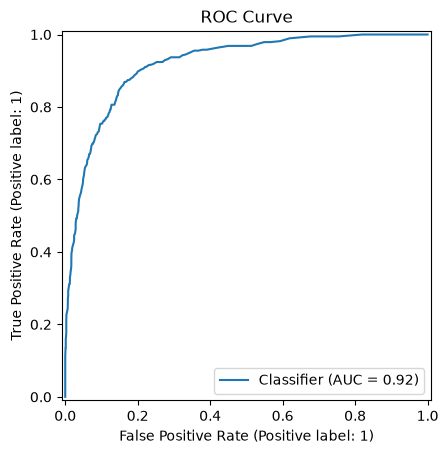

In [24]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title("ROC Curve")
plt.show()

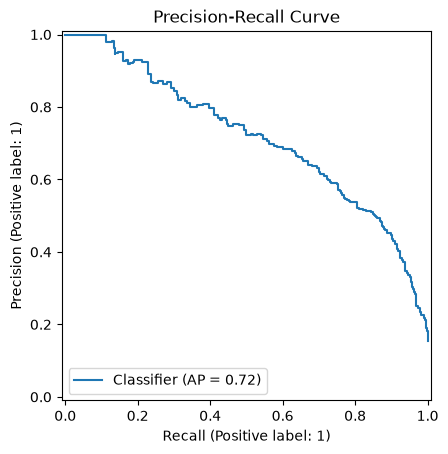

In [25]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(y_test, y_prob)

plt.title("Precision-Recall Curve")
plt.show()

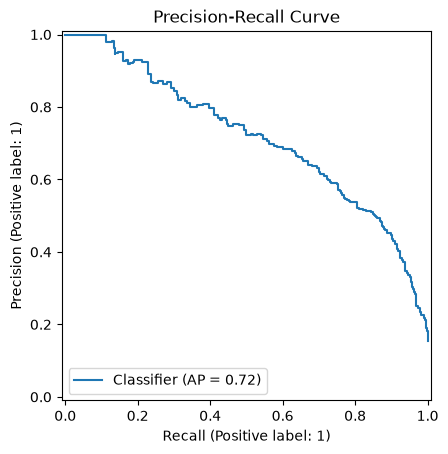

In [26]:
# Import the Precision-Recall curve display tool
from sklearn.metrics import PrecisionRecallDisplay

# Plot precision against recall using the predicted probabilities
PrecisionRecallDisplay.from_predictions(y_test, y_prob)

# Add a title
plt.title("Precision-Recall Curve")

# Display the chart
plt.show()

                               Feature  Importance
8                      num__PageValues    0.332583
7                       num__ExitRates    0.091110
5         num__ProductRelated_Duration    0.078903
4                  num__ProductRelated    0.071518
6                     num__BounceRates    0.056070
1         num__Administrative_Duration    0.046493
0                  num__Administrative    0.039527
17                      cat__Month_Nov    0.023512
3          num__Informational_Duration    0.019878
2                   num__Informational    0.016959
51                  cat__TrafficType_2    0.011307
16                      cat__Month_May    0.010390
41                       cat__Region_1    0.009163
72  cat__VisitorType_Returning_Visitor    0.007861
70        cat__VisitorType_New_Visitor    0.007802


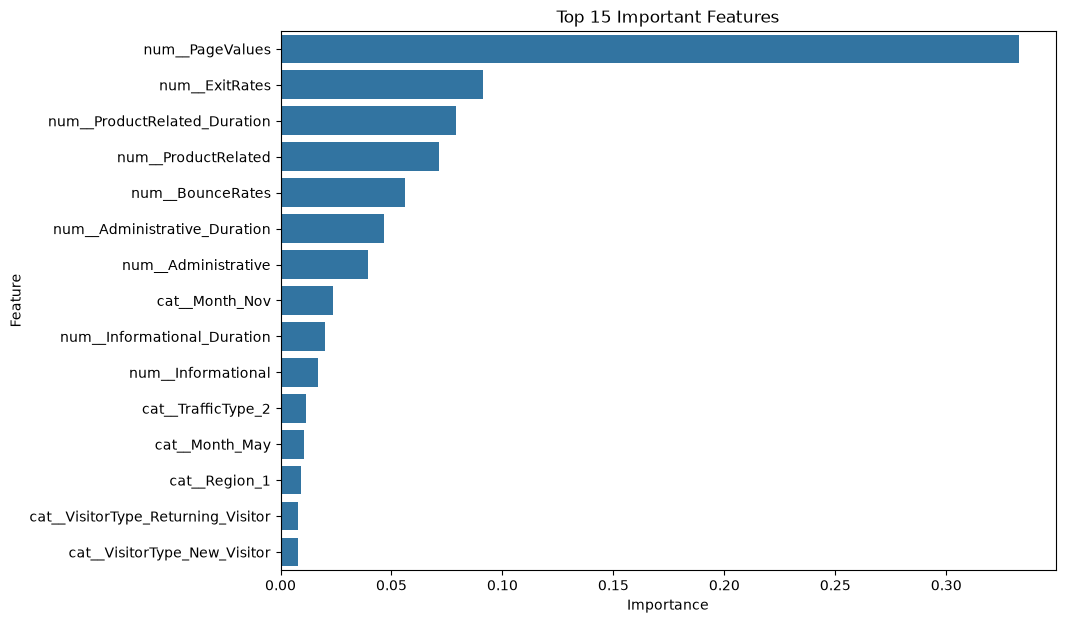

In [27]:
# Feature importance is directly available for Random Forest models
if best_model_name in ["Random Forest", "Tuned Random Forest"]:

    # Get the names of the features after preprocessing
    feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

    # Get the importance score assigned to each feature by Random Forest
    importances = best_model.named_steps["classifier"].feature_importances_

    # Create a DataFrame containing feature names and their importance scores
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })

    # Sort features from most important to least important
    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    )

    # Display the 15 most important features
    print(importance_df.head(15))

    # Create a chart showing the top 15 features
    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=importance_df.head(15),
        x="Importance",
        y="Feature"
    )

    # Add chart title
    plt.title("Top 15 Important Features")

    # Display the chart
    plt.show()

else:
    # Display this message if the selected model is not Random Forest
    print("Feature importance chart is available for Random Forest models.")

In [28]:
# Import joblib to save the trained model
import joblib

# Save the complete pipeline, including preprocessing and the classifier
joblib.dump(best_model, "purchase_intent_model.pkl")

# Confirm that the model has been saved
print("Model saved successfully!")

Model saved successfully!
